# Data Visualization

Ici, nous commencons par visualiser les données

In [ ]:
import os
import sys
sys.path.append("../../modules")

from intern.ihf.ban import extract as extract

In [11]:
import importlib
importlib.reload(extract)

<module 'intern.ihf.ban.extract' from 'c:\\Groupe_KC_AHA_Python\\main\\ihf\\../../modules\\intern\\ihf\\ban\\extract.py'>

In [12]:
df = extract.read_ban_file(extract.BAN_ADRESS_FILES[0])
df.head()

,id,id_fantoir,numero,rep,nom_voie,code_postal,code_insee,nom_commune,code_insee_ancienne_commune,nom_ancienne_commune,...,lat,type_position,alias,nom_ld,libelle_acheminement,nom_afnor,source_position,source_nom_voie,certification_commune,cad_parcelles
0,04005_0008_00015,04005_0008,15,NaN,Rue de l’Eglise,4170,4005,Allons,NaN,NaN,...,43.977500,bâtiment,NaN,NaN,ALLONS,RUE DE L EGLISE,commune,commune,1,NaN
1,04005_0002_00004,04005_0002,4,NaN,Place d’Autane,4170,4005,Allons,NaN,NaN,...,43.977030,bâtiment,NaN,NaN,ALLONS,PLACE D AUTANE,commune,commune,1,NaN
2,04005_0020_00124,04005_0020,124,NaN,Rue Amiral de Richery,4170,4005,Allons,NaN,NaN,...,43.977064,bâtiment,NaN,NaN,ALLONS,RUE AMIRAL DE RICHERY,commune,commune,1,NaN
3,04005_0002_00007,04005_0002,7,NaN,Place d’Autane,4170,4005,Allons,NaN,NaN,...,43.977040,bâtiment,NaN,NaN,ALLONS,PLACE D AUTANE,commune,commune,1,NaN
4,04005_0012_00001,04005_0012,1,NaN,Rue du Fort,4170,4005,Allons,NaN,NaN,...,43.978099,bâtiment,NaN,NaN,ALLONS,RUE DU FORT,commune,commune,1,NaN


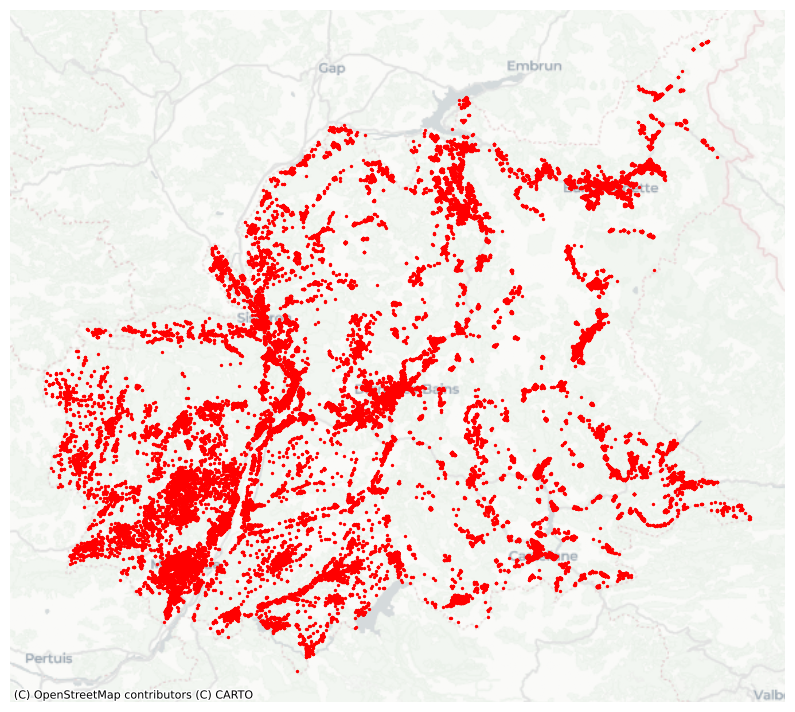

In [22]:
import geopandas as gpd
import contextily as cx

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326",
).to_crs(epsg=3857)

ax = gdf.plot(markersize=2, color="red", figsize=(10, 10))
p = cx.providers.CartoDB.Positron(apikey="cb1_5bwe_1_9ba5234936bb78fffbab1218")
cx.add_basemap(ax, source=p)
ax.set_axis_off()